# Occultations.jl – quick start

A short tour of the basic usage with a real event: the occultation of the star Gaia DR2 4367203805493754752 by the trans-Neptunian object (174567) Varda on 2018 September 10 ([Souami et al. 2020](https://doi.org/10.1051/0004-6361/202038526)).

1. the star and the body,
2. the **prediction** of the event and the map of its shadow path,
3. the observed chords,
4. the limb fit and the astrometry,
5. the uncertainties (posterior),
6. the post-fit map.

The notebook runs offline: the ephemeris of Varda comes from a JPL Horizons table stored with the examples. It needs the packages `Occultations` (this repository), `Plots` and, for the maps, `CairoMakie`. The [manual](https://mkretlow.github.io/Occultations.jl/) explains every step in detail.

In [1]:
import Pkg
Pkg.activate(dirname(pwd()))            # the Occultations.jl repository (this notebook lies in examples/)

In [2]:
using Occultations, Plots
import CairoMakie                       # draws the maps (install it in your default environment: Pkg.add("CairoMakie"))
gr(fmt=:png); CairoMakie.activate!(type="png")   # figures as PNG in the notebook

## 1. The star and the body

The star at the epoch of the event (from Gaia), and the body with its ephemeris. Here the ephemeris is a stored JPL Horizons table (UTC, RA and Dec in degrees, distance in km); with `using HTTP` it can be fetched online instead:

```julia
using HTTP
eph = horizons_ephem("174567", "2018-09-10T03:00", "2018-09-10T04:00")
```

In [3]:
star = Star("17 18 25.12481", "-02 05 14.4282"; name="Gaia DR2 4367203805493754752", epoch=2018.69, ra_err=0.2, dec_err=0.1, mag=Dict("G" => 14.7))

file = joinpath(pkgdir(Occultations), "examples", "data", "varda_horizons_20180910.txt")
rows = [split(l) for l in eachline(file) if !startswith(l, "#")]
eph  = EphemTable(first.(rows), parse.(Float64, getindex.(rows, 2)), parse.(Float64, getindex.(rows, 3)),
                  parse.(Float64, getindex.(rows, 4)); name="Varda")
body = Body("Varda", eph; radius=370.0)          # radius in km

Body Varda
  ephemeris: EphemTable(Varda, 41 points, 2018-09-10T03:15:00.0000 + 0.67 h)
  radius = 370.000 km


## 2. Prediction

`predict` searches a time interval for occultations of a star (or a list of stars) by the body: the closest approach as seen from the centre of the Earth, the shadow velocity, the distance and the point on the Earth below the shadow centre.

In [4]:
predict(star, body, "2018-09-10T03:20", "2018-09-10T03:50")

1 predicted occultation(s)
 epoch (UTC)                star RA (ICRS)  Dec               C/A ["]    P/A    vel        dist      mag   shadow centre
 2018-09-10T03:39:34.769  17 18 25.1248 -02 05 14.428  CA= 0.1020"  PA= 73.85  vel= 10.86 km/s  D= 46.638 au  mag=14.70  lon=-112.629 lat=  6.964


An `Event` holds one occultation: star, body and closest approach, and later the observed chords.

In [5]:
ev = Event(star, body, "2018-09-10T03:34"; window=900)    # closest approach searched within ±900 s (inside the table)

Event Varda, 2018-09-10T03:39:35: Varda occults Star(Gaia DR2 4367203805493754752, RA=17 18 25.1248, Dec=-02 05 14.428)
  closest approach 2018-09-10T03:39:34.769: 0.1020" (3450.7 km), PA 73.85°, 10.856 km/s, distance 46.6379 au


The predicted shadow path on a map, with its uncertainty for an assumed ephemeris error of 20 mas (time marks every minute):

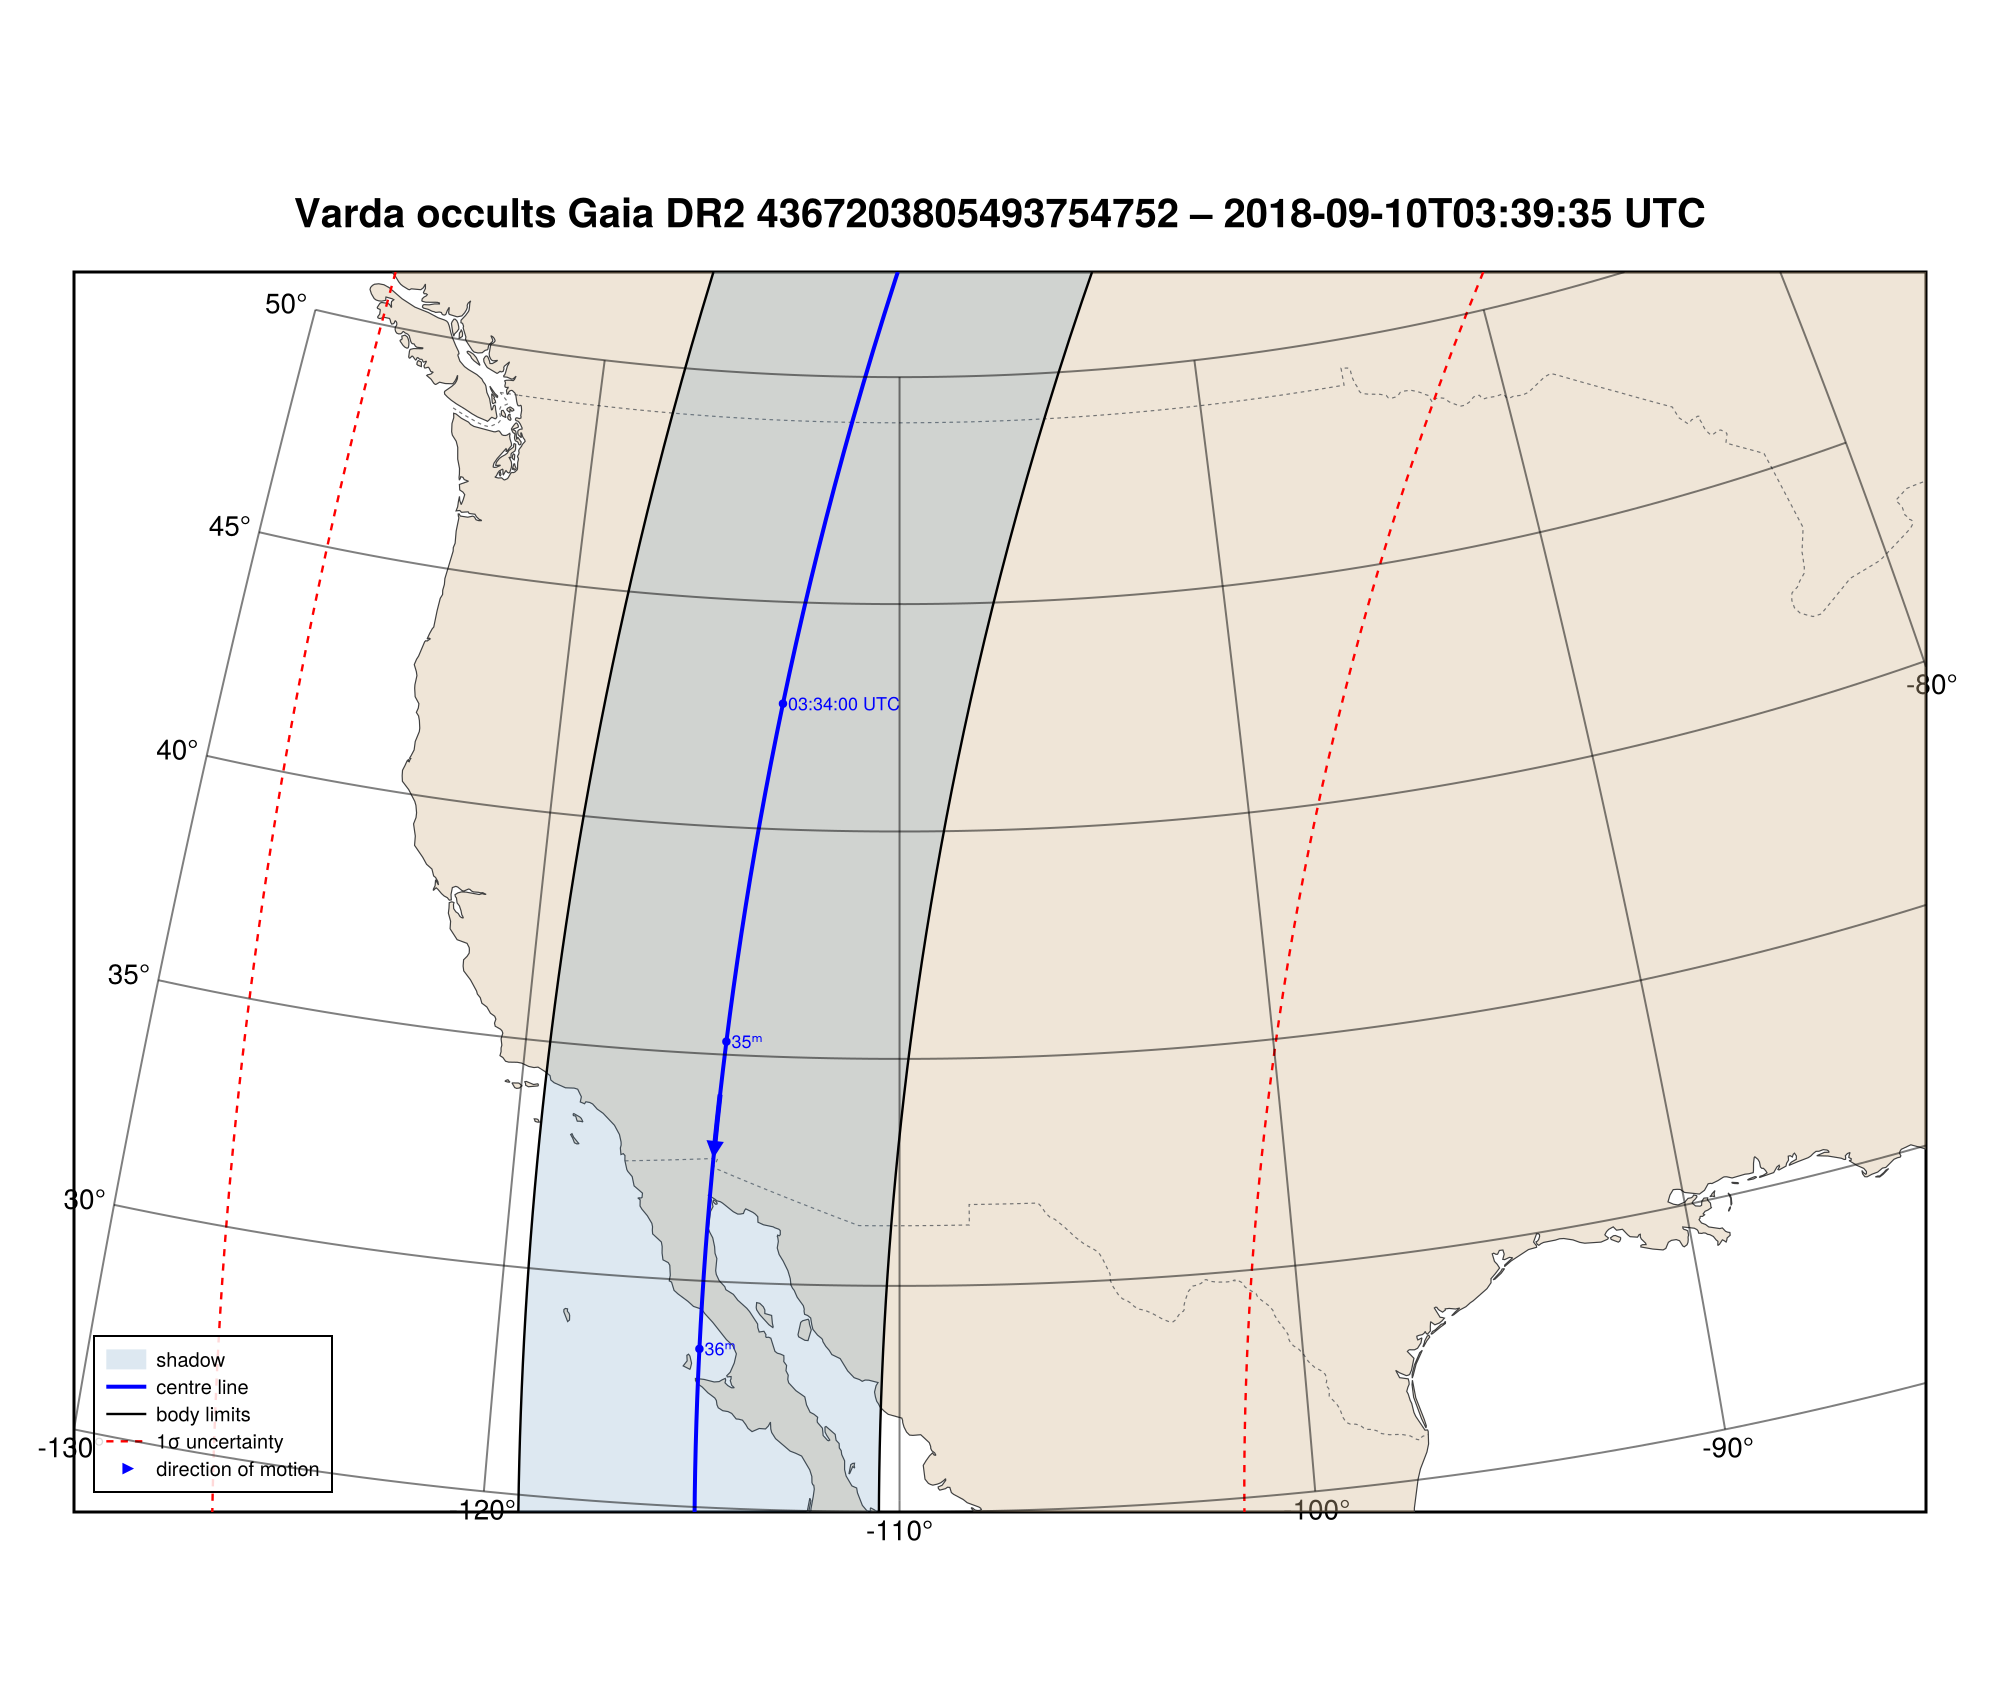

In [6]:
geomap(ev; window=600, error_mas=20, projection="+proj=laea +lon_0=-110 +lat_0=38", limits=(-130, -85, 25, 50))

## 3. The observations

Each station gives a chord: its position (longitude east, latitude, altitude in m) and the times of disappearance (immersion) and reappearance (emersion) of the star with their 1σ errors in s. A station that did not see the occultation gives a negative chord with the time span it observed. Here the published timings of Souami et al. (2020).

In [7]:
day = "2018-09-10T"
for (name, lon, lat, alt, ti, σi, te, σe) in [
        ("TWF", "-114 28 13.1", "42 35 01.9", 1133, "03:32:57.10", 0.60, "03:33:58.83", 0.60),
        ("MHV", "-114 35 48.9", "35 01 54.1",  184, "03:33:56.99", 0.76, "03:35:05.27", 0.30),
        ("YMA", "-114 26 10.5", "32 39 34.0",   97, "03:34:17.10", 0.60, "03:35:26.39", 0.59),
        ("CAR", "-111 57 07.9", "33 48 42.9",  654, "03:34:12.39", 0.47, "03:35:19.52", 0.47),
        ("FLO", "-111 21 00.6", "33 00 54.3",  484, "03:34:23.30", 0.13, "03:35:26.75", 0.15)]
    push!(ev, Chord(name, Observer(name, lon, lat, alt); immersion=day * ti, immersion_err=σi,
                    emersion=day * te, emersion_err=σe))
end
push!(ev, Chord("GAR", Observer("GAR", "-119 40 20.3", "38 53 23.5", 1502); span=(day * "03:28", day * "03:42")))
ev

Event Varda, 2018-09-10T03:39:35: Varda occults Star(Gaia DR2 4367203805493754752, RA=17 18 25.1248, Dec=-02 05 14.428)
  closest approach 2018-09-10T03:39:34.769: 0.1020" (3450.7 km), PA 73.85°, 10.856 km/s, distance 46.6379 au
  Chord(TWF, positive)
  Chord(MHV, positive)
  Chord(YMA, positive)
  Chord(CAR, positive)
  Chord(FLO, positive)
  Chord(GAR, negative)


The chords in the sky plane of the body (f, g in km; east to the left, as on the sky):

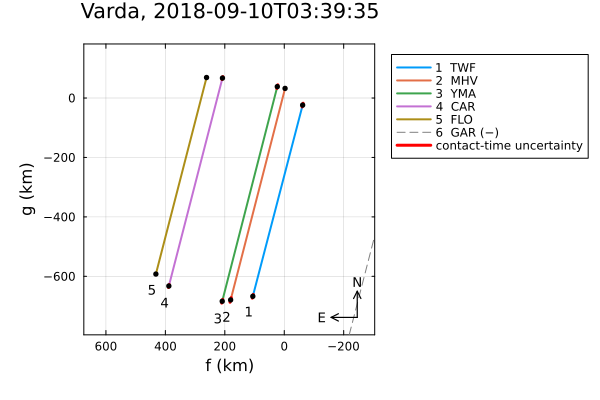

In [8]:
plot(ev)

## 4. The limb fit and the astrometry

`fit_limb` fits an ellipse (apparent semi-major axis a′, oblateness ε′ = 1 − b′/a′, position angle φ′ of the minor axis) and its centre to the contact times; the negative chord is a constraint: the limb must not cross it. Every value comes with its 1σ error.

In [9]:
r = fit_limb(ev)

LimbProblem fit: χ² = 8.469, dof = 5, χ²/dof = 1.694
  center_f               =     189.341701 ± 3.207988
  center_g               =    -301.535492 ± 1.731132
  equatorial_radius      =     383.238903 ± 3.376490
  oblateness             =       0.069620 ± 0.049522
  position_angle         =      72.546799 ± 4.417765
  derived:
  offset_ra              =       5.597661 ± 0.094840
  offset_dec             =      -8.914537 ± 0.051179
  equivalent_radius      =     369.657619 ± 6.936290
  semi_minor_axis        =     356.557630 ± 16.116883


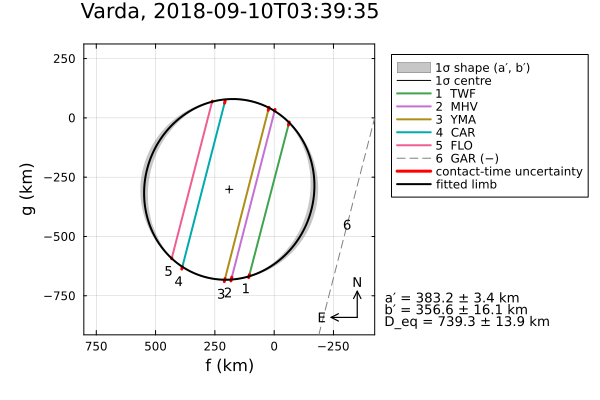

In [10]:
plot(r)

In [11]:
r[:equatorial_radius], r[:semi_minor_axis], 2 .* r[:equivalent_radius]     # a′, b′, D_eq in km: (value, σ)

((383.23890266466594, 3.376490107081499), (356.5576303847268, 16.116883071656876), (739.3152372441846, 13.872580112572876))

The fitted centre is the offset of the body from its ephemeris, i.e. its astrometric position:

In [12]:
astrometry(r)

(epoch = Epoch("2018-09-10T03:39:34.7694"), ra = 259.60471550169234, dec = -2.0873357596675506, ra_err = 0.22134744205637777, dec_err = 0.11233554749073074, offset_ra = 5.597661195108491, offset_dec = -8.914536595810807, offset_ra_err = 0.09484034007162516, offset_dec_err = 0.05117885530218726, ra_str = "17 18 25.13172", dec_str = "-02 05 14.4087")

## 5. Uncertainties: the posterior

Sampling the posterior (MCMC) shows the uncertainties beyond the linear approximation; the corner plot compares them with the published values.

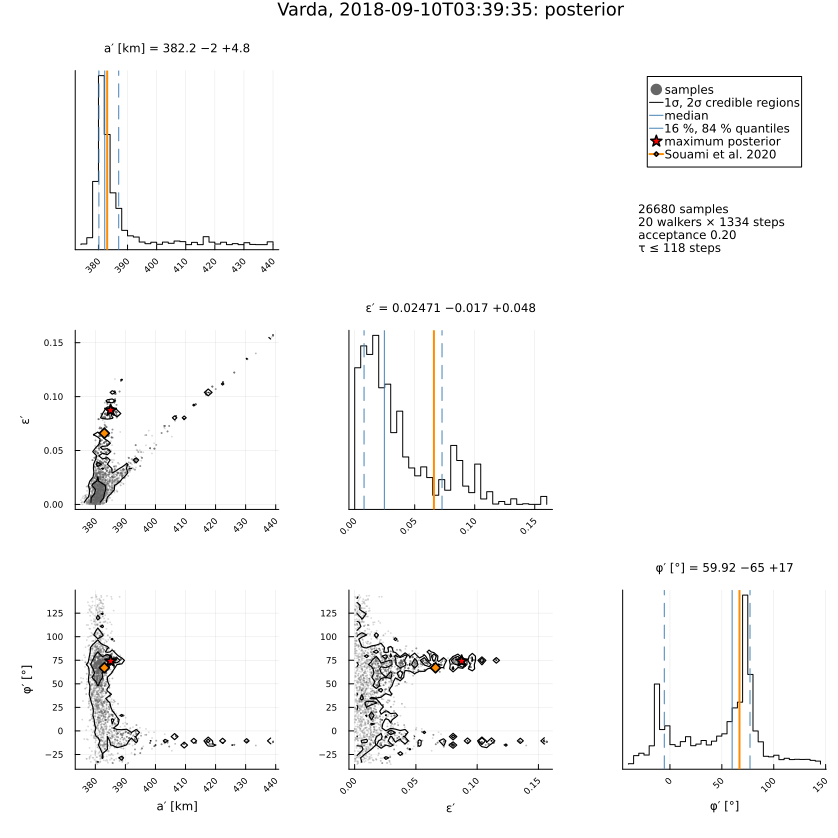

In [13]:
post = sample(r; nsteps=2000)
cornerplot(post; vars=[:equatorial_radius, :oblateness, :position_angle],
           axislabels=Dict(:equatorial_radius => "a′ [km]", :oblateness => "ε′", :position_angle => "φ′ [°]"),
           truths=Dict(:equatorial_radius => 383.0, :oblateness => 0.066, :position_angle => 67.0),
           truth_label="Souami et al. 2020")

## 6. The post-fit shadow path

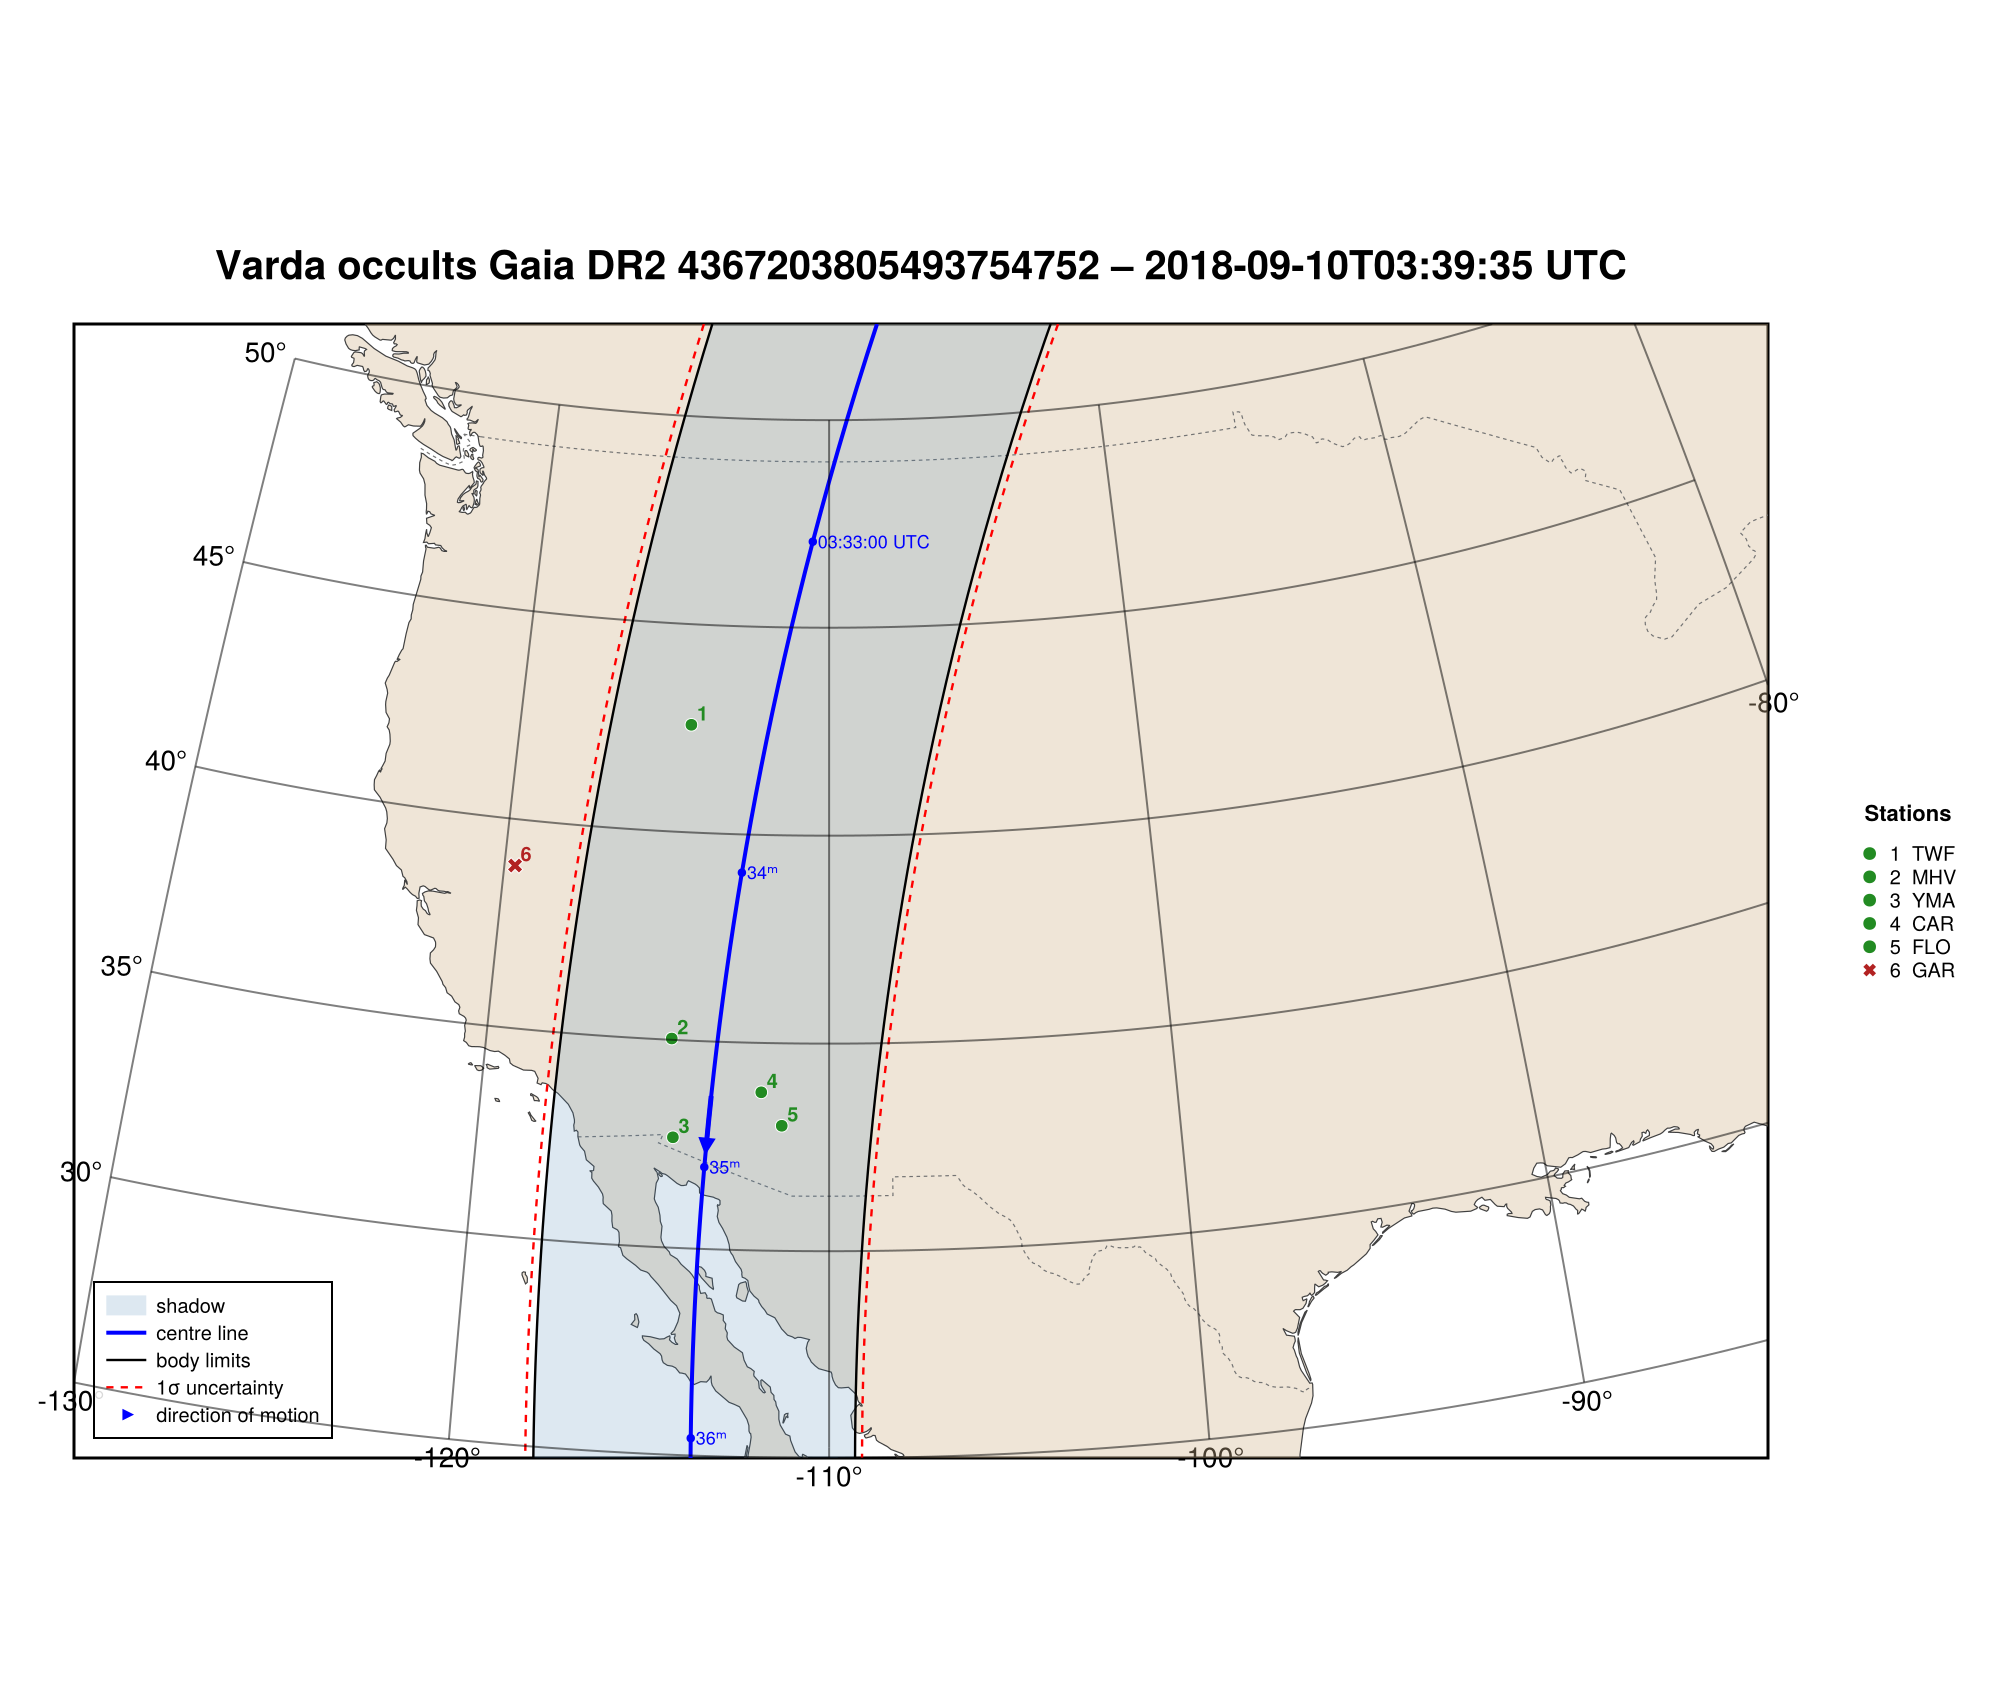

In [14]:
geomap(r; window=600, projection="+proj=laea +lon_0=-110 +lat_0=38", limits=(-130, -85, 25, 50))

## Next steps

* **Your own light curves:** `lc = read_lightcurve("station.csv"; format=:pymovie)` (also Tangra, AstroImageJ, text), then `fit_timing(lc; vel, dist, star_diam)` gives the contact times with a diffraction model, and `Chord(name, observer, timingfit)` the chord.
* **Observation reports** in the CORA format: `cora_chord(read_cora_report("report.txt"))`.
* **More:** three-dimensional shapes from several events, binaries and contact binaries, rings, atmospheres – see the [manual](https://mkretlow.github.io/Occultations.jl/) and the other examples in this folder (`tutorial.jl` covers them with simulated data).